In [139]:
import pandas as pd

df = pd.read_excel("MEDAL RESULT BY COUNTRY 49.xlsx")
df


,year,host_country,country,region,gdp_tier,sports_investment,athletes_sent,total_medals,medal_points,medal_efficiency_pct
0,1992,Spain,United States,North America,High,High,287,48,90,16.725
1,1992,Spain,China,Asia,High,High,220,29,55,13.182
2,1992,Spain,Russia,Europe,Medium,High,171,25,47,14.620
3,1992,Spain,Great Britain,Europe,High,High,139,21,44,15.108
4,1992,Spain,Germany,Europe,High,High,143,15,37,10.490
...,...,...,...,...,...,...,...,...,...,...
905,2026,Italy,Estonia,Europe,High,Medium,7,1,3,14.286
906,2026,Italy,Lithuania,Europe,Medium,Medium,19,2,4,10.526
907,2026,Italy,Uzbekistan,Asia,Low,Medium,45,1,1,2.222
908,2026,Italy,Armenia,Europe/Asia,Low,Medium,2,2,4,100.000


In [140]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 910 entries, 0 to 909
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   year                  910 non-null    int64  
 1   host_country          910 non-null    str    
 2   country               910 non-null    str    
 3   region                910 non-null    str    
 4   gdp_tier              910 non-null    str    
 5   sports_investment     910 non-null    str    
 6   athletes_sent         910 non-null    int64  
 7   total_medals          910 non-null    int64  
 8   medal_points          910 non-null    int64  
 9   medal_efficiency_pct  910 non-null    float64
dtypes: float64(1), int64(4), str(5)
memory usage: 99.3 KB


In [141]:
df.head()

,year,host_country,country,region,gdp_tier,sports_investment,athletes_sent,total_medals,medal_points,medal_efficiency_pct
0,1992,Spain,United States,North America,High,High,287,48,90,16.725
1,1992,Spain,China,Asia,High,High,220,29,55,13.182
2,1992,Spain,Russia,Europe,Medium,High,171,25,47,14.620
3,1992,Spain,Great Britain,Europe,High,High,139,21,44,15.108
4,1992,Spain,Germany,Europe,High,High,143,15,37,10.490


In [142]:
df.describe()

,year,athletes_sent,total_medals,medal_points,medal_efficiency_pct
count,910.000000,910.000000,910.000000,910.000000,910.000000
mean,2008.896703,51.876923,6.620879,13.032967,31.832688
std,10.361788,66.845916,9.201461,18.231581,66.215414
min,1992.000000,1.000000,1.000000,1.000000,1.562000
25%,2000.000000,13.000000,2.000000,3.000000,8.333000
50%,2008.000000,28.000000,3.000000,6.000000,12.500000
75%,2018.000000,59.750000,7.000000,13.750000,20.000000
max,2026.000000,398.000000,63.000000,114.000000,600.000000


In [143]:
df.dtypes

year                      int64
host_country                str
country                     str
region                      str
gdp_tier                    str
sports_investment           str
athletes_sent             int64
total_medals              int64
medal_points              int64
medal_efficiency_pct    float64
dtype: object

In [144]:
df.isnull().sum()

year                    0
host_country            0
country                 0
region                  0
gdp_tier                0
sports_investment       0
athletes_sent           0
total_medals            0
medal_points            0
medal_efficiency_pct    0
dtype: int64

In [145]:
df.corr(numeric_only=True)["total_medals"]

year                    0.012893
athletes_sent           0.943418
total_medals            1.000000
medal_points            0.993338
medal_efficiency_pct   -0.095052
Name: total_medals, dtype: float64

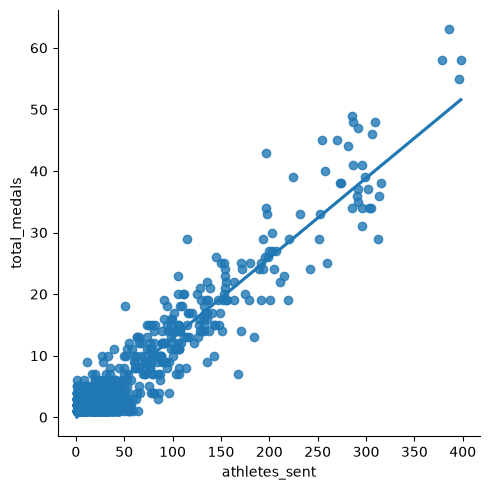

In [146]:
import seaborn as sns

sns.lmplot(
    x="athletes_sent",
    y="total_medals",
    data=df,
    fit_reg=True,
    ci=None
)


<Axes: ylabel='Frequency'>

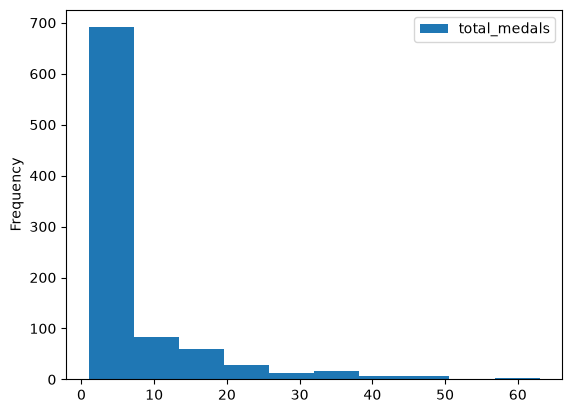

In [147]:
df.plot.hist(y="total_medals")

In [148]:
df[df.isnull().any(axis=1)]

,year,host_country,country,region,gdp_tier,sports_investment,athletes_sent,total_medals,medal_points,medal_efficiency_pct


In [149]:
df.columns

Index(['year', 'host_country', 'country', 'region', 'gdp_tier',
       'sports_investment', 'athletes_sent', 'total_medals', 'medal_points',
       'medal_efficiency_pct'],
      dtype='str')

In [150]:
from sklearn.preprocessing import LabelEncoder
country_encoder=LabelEncoder()
host_country=LabelEncoder()
region=LabelEncoder()
sports_investment=LabelEncoder()
gdp_tier=LabelEncoder()
df["country"]=country_encoder.fit_transform(df["country"])
df["host_country"]=host_country.fit_transform(df["host_country"])
df["region"]=region.fit_transform(df["region"])
df["sports_investment"]=sports_investment.fit_transform(df["sports_investment"])
df["gdp_tier"]=gdp_tier.fit_transform(df["gdp_tier"])
df.head()

,year,host_country,country,region,gdp_tier,sports_investment,athletes_sent,total_medals,medal_points,medal_efficiency_pct
0,1992,11,58,4,0,0,287,48,90,16.725
1,1992,11,10,1,0,0,220,29,55,13.182
2,1992,11,46,2,2,0,171,25,47,14.620
3,1992,11,23,2,0,0,139,21,44,15.108
4,1992,11,22,2,0,0,143,15,37,10.490


In [151]:
x=df[['year', 'host_country', 'country', 'region', 'gdp_tier',
       'sports_investment', 'athletes_sent','medal_points',
       'medal_efficiency_pct']]
y=df['total_medals']

In [152]:
split=int(len(df)*0.8)

x_train=x.iloc[:split]
x_test=x.iloc[split:]

y_train=y.iloc[:split]
y_test=y.iloc[split:]

In [153]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(728, 9)
(182, 9)
(728,)
(182,)


In [154]:
from sklearn.linear_model import LinearRegression
model= LinearRegression()
model.fit(x_train,y_train)
reg_pred= model.predict(x_test)

In [155]:
test= pd.DataFrame({"country":x_test["country"].values,
                    "actual medals":y_test,
                    "predicted medals": reg_pred
                   })
test.head()

,country,actual medals,predicted medals
728,57,6,5.439243
729,52,3,2.840678
730,15,5,5.175390
731,53,1,1.371816
732,3,4,4.977415


In [156]:
test["predicted medals"]=test["predicted medals"].round()
test.head()

,country,actual medals,predicted medals
728,57,6,5.0
729,52,3,3.0
730,15,5,5.0
731,53,1,1.0
732,3,4,5.0


In [157]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
import numpy as np
mae=mean_absolute_error(test["actual medals"],test["predicted medals"])
mse= mean_squared_error(test["actual medals"],test["predicted medals"])
r2=r2_score(test["actual medals"],test["predicted medals"])
rsme=np.sqrt(mse)

print("\nMEAN ABSOLUTE ERROR:--",mae)

print("\nMEAN SQUARED ERROR:--",mse)

print("\nr2_score:--",r2)

print("\nRSME:--",rsme)

print("\n R2 percentage:--",r2 * 100,"%")




MEAN ABSOLUTE ERROR:-- 0.6153846153846154

MEAN SQUARED ERROR:-- 0.945054945054945

r2_score:-- 0.9867261440347366

RSME:-- 0.9721393650372075

 R2 percentage:-- 98.67261440347366 %


In [158]:
df.describe()["total_medals"]

count    910.000000
mean       6.620879
std        9.201461
min        1.000000
25%        2.000000
50%        3.000000
75%        7.000000
max       63.000000
Name: total_medals, dtype: float64

In [159]:
errors=(test["actual medals"]-test["predicted medals"]).abs()
errors

728    1.0
729    0.0
730    0.0
731    0.0
732    1.0
      ... 
905    0.0
906    0.0
907    0.0
908    0.0
909    0.0
Length: 182, dtype: float64

In [160]:
train_r2=model.score(x_train,y_train)
print("training r2:",train_r2)

training r2: 0.9876310518803068


In [161]:
test_r2=model.score(x_test,y_test)
print("testing r2:",test_r2)

testing r2: 0.988142575357702


In [162]:
print(test.columns)

Index(['country', 'actual medals', 'predicted medals'], dtype='str')


In [163]:
test["country"]=country_encoder.inverse_transform(test["country"].astype(int))
test

,country,actual medals,predicted medals
728,Ukraine,6,5.0
729,Sweden,3,3.0
730,Denmark,5,5.0
731,Switzerland,1,1.0
732,Austria,4,5.0
...,...,...,...
905,Estonia,1,1.0
906,Lithuania,2,2.0
907,Uzbekistan,1,1.0
908,Armenia,2,2.0


In [164]:
test[test["country"]=="Germany"]

,country,actual medals,predicted medals
772,Germany,7,9.0
815,Germany,22,22.0
867,Germany,17,16.0


In [165]:
test[test["country"]=="India"]

,country,actual medals,predicted medals
738,India,1,2.0
840,India,2,1.0


In [166]:
print("training years",sorted(x_test["year"].unique()))

training years [np.int64(2020), np.int64(2022), np.int64(2024), np.int64(2026)]


In [167]:
print("testing years",sorted(x_test["year"].unique()))

testing years [np.int64(2020), np.int64(2022), np.int64(2024), np.int64(2026)]


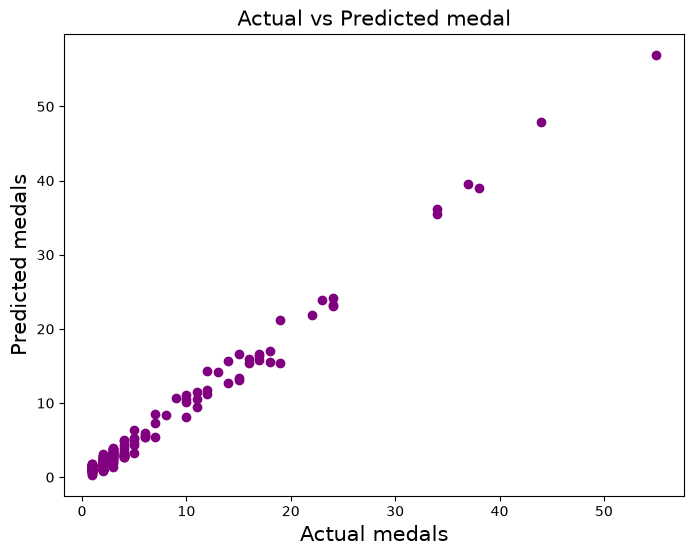

In [168]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.scatter(y_test,reg_pred,color="purple")
plt.title("Actual vs Predicted medal",size=15)
plt.xlabel("Actual medals",size=15)
plt.ylabel("Predicted medals",size=15)
plt.show()


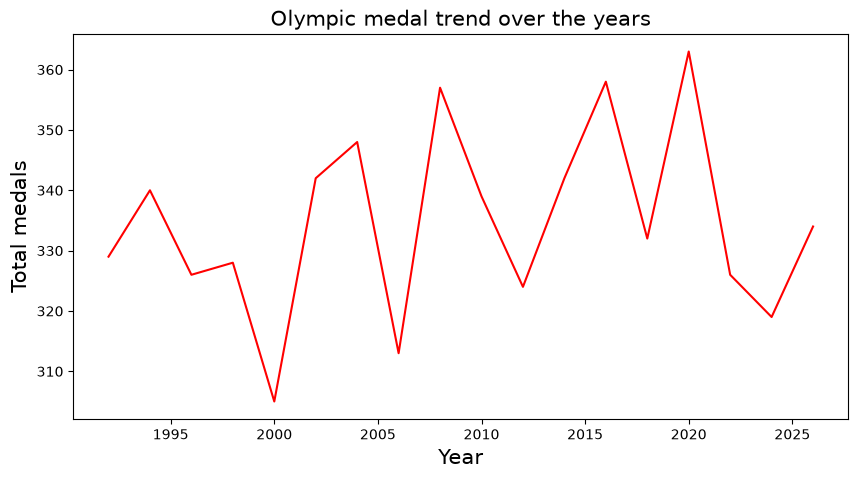

In [169]:
plt.figure(figsize=(10,5))
plt.plot(df.groupby("year")
["total_medals"].sum(),color="red")

plt.xlabel("Year",size=15)
plt.ylabel("Total medals",size=15)
plt.title("Olympic medal trend over the years",size=15)
plt.show()

In [170]:
df["country"].head(20)

0     58
1     10
2     46
3     23
4     22
5      2
6     20
7     31
8     50
9     29
10    39
11    25
12    42
13     9
14    40
15    13
16    33
17     8
18    51
19    57
Name: country, dtype: int64

In [171]:
print(country_encoder.classes_)

['Argentina' 'Armenia' 'Australia' 'Austria' 'Azerbaijan' 'Bahrain'
 'Belarus' 'Belgium' 'Brazil' 'Canada' 'China' 'Colombia' 'Croatia' 'Cuba'
 'Czech Republic' 'Denmark' 'Dominican Republic' 'Estonia' 'Ethiopia'
 'Finland' 'France' 'Georgia' 'Germany' 'Great Britain' 'Greece' 'Hungary'
 'India' 'Indonesia' 'Iran' 'Italy' 'Jamaica' 'Japan' 'Kazakhstan' 'Kenya'
 'Latvia' 'Lithuania' 'Mexico' 'Mongolia' 'Morocco' 'Netherlands'
 'New Zealand' 'North Korea' 'Norway' 'Philippines' 'Poland' 'Romania'
 'Russia' 'Slovakia' 'Slovenia' 'South Africa' 'South Korea' 'Spain'
 'Sweden' 'Switzerland' 'Thailand' 'Turkey' 'Uganda' 'Ukraine'
 'United States' 'Uzbekistan']


In [172]:
df["country"]=country_encoder.inverse_transform(df["country"])
df["country"].head(20)

0     United States
1             China
2            Russia
3     Great Britain
4           Germany
5         Australia
6            France
7             Japan
8       South Korea
9             Italy
10      Netherlands
11          Hungary
12           Norway
13           Canada
14      New Zealand
15             Cuba
16            Kenya
17           Brazil
18            Spain
19          Ukraine
Name: country, dtype: str

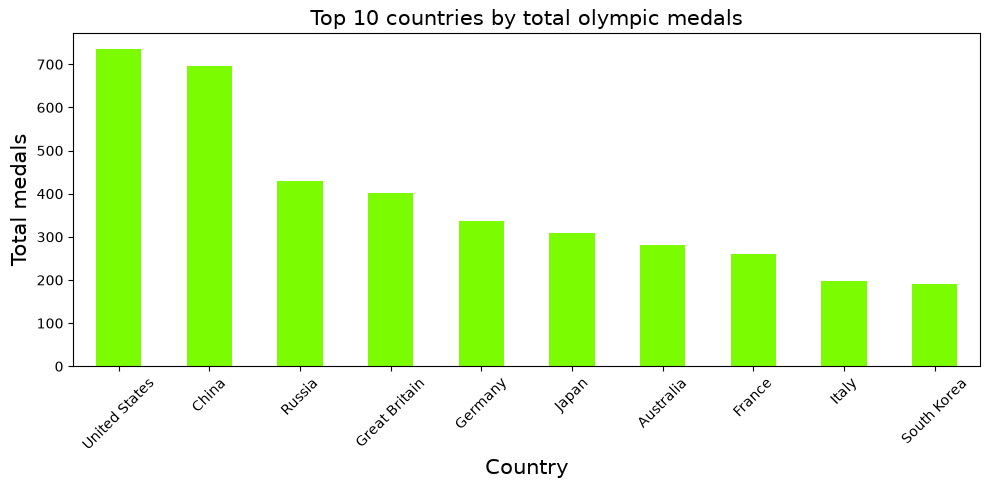

In [173]:
top=df.groupby("country")["total_medals"].sum().sort_values(ascending=False).head(10)
top.plot(kind="bar",figsize=(10,5),color="lawngreen")
plt.xlabel("Country",size=15)
plt.ylabel("Total medals",size=15)
plt.title("Top 10 countries by total olympic medals",size=15)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()